<a href="https://colab.research.google.com/github/NadiaSultanaSuchi/CVPR-CNN-Assignment/blob/main/CNN_23_53645_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN Development on Custom Dataset

Nadia Sultana Suchi, ID 23-53645-3

In this notebook, I built a custom CNN on 10 classes of the NWPU RESISC45 dataset. I trained it, tested it and saved it.

## 1. Import Libraries

This cell imports PyTorch, torchvision, numpy, matplotlib and the Hugging Face datasets library. The model runs on the GPU if one is available. In this run, cuda was used.

In [1]:
!pip install -q datasets torchsummary
from torchvision import datasets
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 2. Load and Explore Dataset

The dataset is NWPU RESISC45. It is a public benchmark for classifying satellite images by scene. It was created by Northwestern Polytechnical University. The full dataset has 45 classes, with 700 images in each class, so 31,500 images in total. Each image is 256 by 256 pixels. The images are satellite photos from many places around the world.

I used the Hugging Face version called timm/resisc45. It already has train, validation and test splits. The dataset card lists the license as other and CC BY SA. I used the data only for learning.

To keep training fast, I chose 10 classes: airport, beach, desert, forest, harbor, industrial area, lake, mountain, rectangular farmland and river. Most of these look different from each other, but some are similar, like river and lake, or forest and mountain. So the task is not too easy.

Citation: Cheng, Han and Lu, 2017, Remote sensing image scene classification: Benchmark and state of the art.

In [2]:
from datasets import load_dataset
raw = load_dataset("timm/resisc45")

all_names = raw['train'].features['label'].names
selected = ['forest', 'river', 'lake', 'beach', 'desert',
            'airport', 'industrial area', 'harbor', 'mountain', 'rectangular farmland']

class_ids = [i for i, n in enumerate(all_names) if n.replace('_', ' ') in selected]
classes = [all_names[i].replace('_', ' ') for i in class_ids]
id_map = {old: new for new, old in enumerate(class_ids)}

# keep only the selected classes
train_raw = raw['train'].filter(lambda l: l in class_ids, input_columns='label')
val_raw = raw['validation'].filter(lambda l: l in class_ids, input_columns='label')
test_raw = raw['test'].filter(lambda l: l in class_ids, input_columns='label')

README.md:   0%|          | 0.00/3.11k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  255MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 85.1MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 85.2MB            

... (3 outputs left out)

Generating test split:   0%|          | 0/6300 [00:00<?, ? examples/s]

Filter:   0%|          | 0/18900 [00:00<?, ? examples/s]

Filter:   0%|          | 0/6300 [00:00<?, ? examples/s]

Filter:   0%|          | 0/6300 [00:00<?, ? examples/s]

After filtering the classes, there are 4214 training images, 1386 validation images and 1400 test images. In the test set, each class has between 115 and 162 images, so the data is fairly balanced. Below, one sample image from each class is shown.

In [3]:
print('Dataset Summary')
print('Train Data: ', len(train_raw))
print('Validation Data: ', len(val_raw))
print('Test Data: ', len(test_raw))
print('Classess and Indices: ', {c: i for i, c in enumerate(classes)})

Dataset Summary
Train Data:  4214
Validation Data:  1386
Test Data:  1400
Classess and Indices:  {'airport': 0, 'beach': 1, 'desert': 2, 'forest': 3, 'harbor': 4, 'industrial area': 5, 'lake': 6, 'mountain': 7, 'rectangular farmland': 8, 'river': 9}


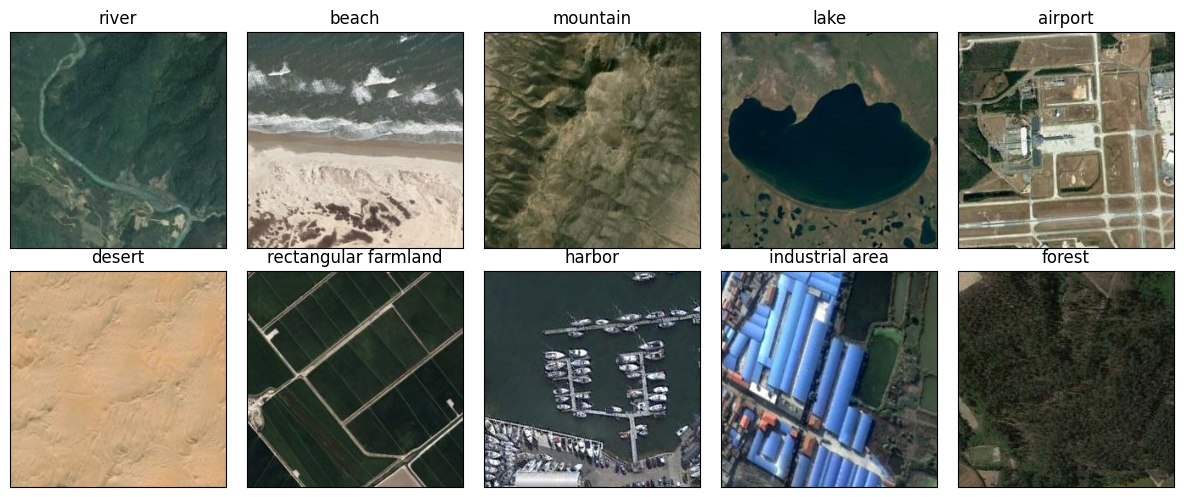

In [4]:
ROWS, COLS = 2, 5
fig, axes = plt.subplots(ROWS, COLS, figsize=(12, 5))
shown = set()
ix = 0
while len(shown) < len(classes):
    item = train_raw[ix]
    c = id_map[item['label']]
    if c not in shown:
        ax = axes.flat[len(shown)]
        ax.imshow(item['image'])
        ax.set_title(classes[c])
        ax.set(xticks=[], yticks=[])
        shown.add(c)
    ix += 1
plt.tight_layout()
plt.show()

## 3. Data Preprocessing and Augmentation

Images are resized from 256 by 256 to 64 by 64. Small images train faster and fit easily in Colab memory. ToTensor changes pixel values to the range 0 to 1.

Augmentation is used only on training data. Satellite images are taken from above, so there is no fixed direction, which makes horizontal and vertical flips safe. A small rotation of 15 degrees and a light color change help the model work with different light and angles. Validation and test data are only resized and converted to tensors, with no augmentation, so the results stay fair.

The RESISCDataset class turns the Hugging Face dataset into a PyTorch Dataset. It also changes the original labels to numbers from 0 to 9.

In [5]:
size = 64
train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

class RESISCDataset(Dataset):
    def __init__(self, hf_data, transform):
        self.hf_data = hf_data
        self.transform = transform

    def __getitem__(self, ix):
        item = self.hf_data[ix]
        img = self.transform(item['image'].convert('RGB'))
        return img, id_map[item['label']]

    def __len__(self):
        return len(self.hf_data)

train_data = RESISCDataset(train_raw, train_transform)
val_data = RESISCDataset(val_raw, val_transform)
test_data = RESISCDataset(test_raw, val_transform)

## Hyperparameters

Batch size is 32. It gives a good balance between memory use and stable training.

Learning rate is 0.001. This is a common starting value for the Adam optimizer.

Epochs are 20. In this dataset, the loss drops a lot within 20 epochs, and more epochs would take more time.

In the DataLoader, training data is shuffled so the model does not memorize the order. Validation and test data are not shuffled.

In [6]:
## HyperParameters ##
batch_size = 32
learning_rate = 1e-3
epoch_number = 20

In [7]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

## 4. Define CNN Architecture

The model has 3 convolution blocks. Each block has Conv2d, BatchNorm, ReLU and MaxPool. The number of filters grows from 32 to 64 to 128. Early layers learn simple things like edges and texture. Later layers learn bigger shapes and patterns. Padding of 1 keeps the image size the same after each convolution.

After 3 MaxPool layers, a 64 by 64 image becomes 8 by 8. After Flatten, there are 128 times 8 times 8, which is 8192 features. After that comes a Linear layer with Dropout 0.5. Dropout stops the model from memorizing the training data, so it reduces overfitting. BatchNorm makes training faster and more stable.

The loss function is CrossEntropyLoss, the standard choice for multi class classification. The optimizer is Adam, because it adjusts the learning rate by itself and converges quickly.

In [8]:
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        #Feature Extraction
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),

        #Classifier
        nn.Flatten(),
        nn.Linear(128*8*8, 256),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(256, len(classes))
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [9]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

The model summary shows the output shape and the number of parameters of each layer. The model has 2,193,674 parameters and its size is 8.37 MB. Almost all parameters are in the first Linear layer after Flatten, so that is the biggest layer.

In [10]:
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3, 64, 64));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
       BatchNorm2d-2           [-1, 32, 64, 64]              64
              ReLU-3           [-1, 32, 64, 64]               0
         MaxPool2d-4           [-1, 32, 32, 32]               0
            Conv2d-5           [-1, 64, 32, 32]          18,496
       BatchNorm2d-6           [-1, 64, 32, 32]             128
              ReLU-7           [-1, 64, 32, 32]               0
         MaxPool2d-8           [-1, 64, 16, 16]               0
            Conv2d-9          [-1, 128, 16, 16]          73,856
      BatchNorm2d-10          [-1, 128, 16, 16]             256
             ReLU-11          [-1, 128, 16, 16]               0
        MaxPool2d-12            [-1, 128, 8, 8]               0
          Flatten-13                 [-1, 8192]               0
           Linear-14                  [

## 5. Training Loop with Validation

In each epoch, the model first learns from the training data. Then it is checked on the validation data. No weights are updated on validation data, so it shows how the model does on new images. The loss and accuracy of every epoch are saved in lists so we can plot them later.

In [11]:
## Training Loop ###
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc = validation(val_dl, model, loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/20] | Train Loss: 1.9119 | Train Accuracy: 37.99% | Val Loss: 1.3143 | Val Accuracy: 56.20%
Epoch [2/20] | Train Loss: 1.5123 | Train Accuracy: 48.50% | Val Loss: 1.0604 | Val Accuracy: 62.48%
Epoch [3/20] | Train Loss: 1.3123 | Train Accuracy: 53.77% | Val Loss: 1.0238 | Val Accuracy: 63.85%
Epoch [4/20] | Train Loss: 1.2685 | Train Accuracy: 56.38% | Val Loss: 0.9407 | Val Accuracy: 68.18%
Epoch [5/20] | Train Loss: 1.2221 | Train Accuracy: 57.59% | Val Loss: 0.9336 | Val Accuracy: 66.74%
Epoch [6/20] | Train Loss: 1.1825 | Train Accuracy: 58.42% | Val Loss: 0.8635 | Val Accuracy: 70.63%
Epoch [7/20] | Train Loss: 1.1898 | Train Accuracy: 58.47% | Val Loss: 0.8544 | Val Accuracy: 69.62%
Epoch [8/20] | Train Loss: 1.0675 | Train Accuracy: 62.96% | Val Loss: 0.8799 | Val Accuracy: 68.18%
Epoch [9/20] | Train Loss: 1.0756 | Train Accuracy: 62.79% | Val Loss: 0.8198 | Val Accuracy: 70.63%
Epoch [10/20] | Train Loss: 1.0612 | Train Accuracy: 64.57% | Val Loss: 0.7714 | Val Accura

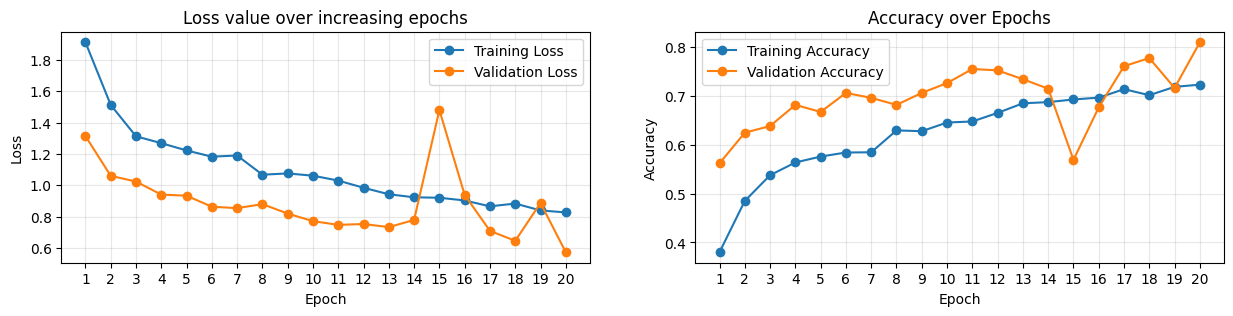

In [12]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Visualizations and Discussion of Curves

Training loss went down from 1.91 to 0.83. Training accuracy went up from 37.99 percent to 72.33 percent. This shows the model is learning properly.

Validation accuracy started at 56.20 percent and reached 81.02 percent at epoch 20. The validation loss also went down to 0.5734, which is the lowest value in the whole run.

In the middle, the validation curve went up and down. The biggest drop was at epoch 15, where validation accuracy fell to 56.93 percent and validation loss rose to 1.4799. It recovered quickly in the next epochs. Possible reasons are the constant learning rate of 0.001, the small validation set, and BatchNorm statistics changing from batch to batch.

Training accuracy is lower than validation accuracy. This is not overfitting. Augmentation and dropout are used in training but not in validation, which makes training harder. The model is still learning, so more epochs could improve the result.

This cell takes one test image and shows the model's prediction and confidence. Confidence is the probability of the predicted class after softmax.

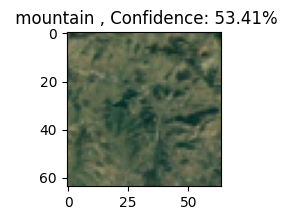

In [13]:
model.eval()
test_img, label = test_data[2]
img = test_img.view(-1, 3, size, size).to(device)

output = model(img)
pred = torch.exp(output)/torch.sum(torch.exp(output))
confidence, index = pred.max(-1)

plt.figure(figsize=(2,2))
plt.imshow(test_img.view(3, size, size).permute(1, 2, 0))
plt.title(f' {classes[index]} , Confidence: {confidence.item()*100:0.2f}%')
plt.show()

## 7. Evaluate Model on Test Set

The model is tested on completely new images that it never saw in training or validation. So this shows its real performance. The model from the last epoch is used here.

In [14]:
test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.59 , Test Accuracy: 80.36%


                      precision    recall  f1-score   support

             airport     0.7559    0.5926    0.6644       162
               beach     0.8276    0.9231    0.8727       130
              desert     0.9313    0.8356    0.8809       146
              forest     0.8704    0.9658    0.9156       146
              harbor     0.9457    0.8592    0.9004       142
     industrial area     0.7486    0.9357    0.8317       140
                lake     0.8108    0.9160    0.8602       131
            mountain     0.6452    0.6957    0.6695       115
rectangular farmland     0.8240    0.7630    0.7923       135
               river     0.6716    0.5882    0.6272       153

            accuracy                         0.8036      1400
           macro avg     0.8031    0.8075    0.8015      1400
        weighted avg     0.8047    0.8036    0.8002      1400



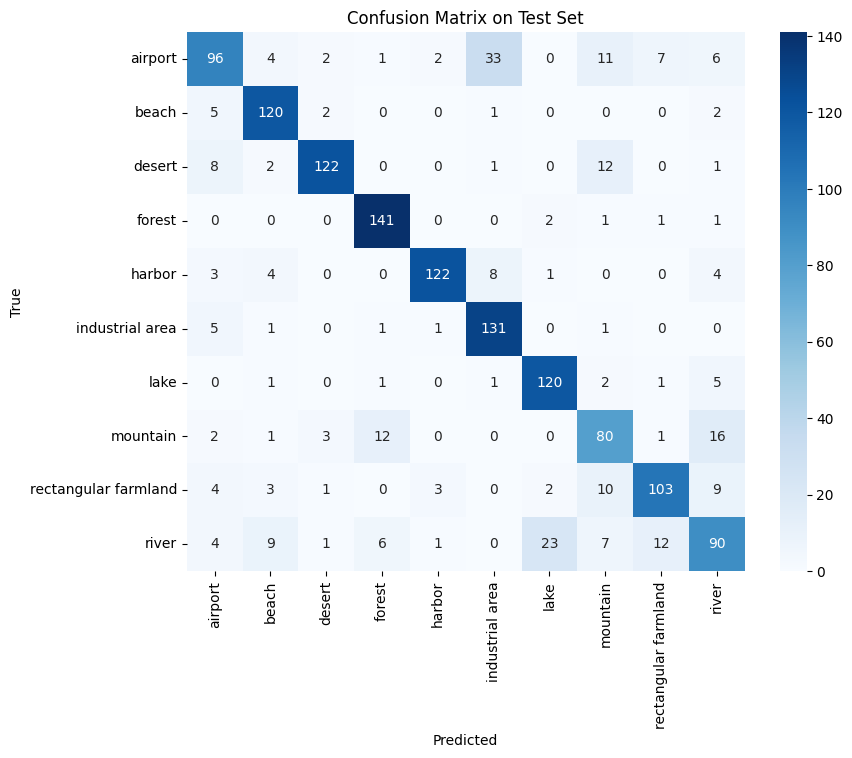

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

@torch.no_grad()
def get_predictions(data_loader, model):
    model.eval()
    preds, labels = [], []
    for x, y in data_loader:
        prediction = model(x.to(device))
        preds.extend(prediction.argmax(-1).cpu().numpy())
        labels.extend(y.numpy())
    return labels, preds

labels, preds = get_predictions(test_dl, model)
print(classification_report(labels, preds, target_names=classes, digits=4))

plt.figure(figsize=(9, 7))
sns.heatmap(confusion_matrix(labels, preds), annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix on Test Set")
plt.show()

Test accuracy is 80.36 percent and test loss is 0.59. This is close to the validation accuracy of 81.02 percent, so the model works on new data and does not overfit.

Results by class:

The best class is forest with an F1 score of 0.92. Next are harbor at 0.90, desert at 0.88, beach at 0.87 and lake at 0.86.

The weakest classes are river, airport and mountain, with F1 scores between 0.63 and 0.67. Airport has a recall of 0.59, which means the model labels many airport images as other classes. River has a precision of 0.67 and a recall of 0.59, so it is mixed up with other classes in both directions. Mountain has a precision of 0.65, so some images of other classes are wrongly called mountain.

Industrial area has a high recall of 0.94 but a lower precision of 0.75. This means the model predicts industrial area quite often, and some images of other classes are wrongly called industrial area.

The confusion matrix shows which classes are mixed up. One possible reason is that small 64 by 64 images lose details like airport runways and mountain peaks.

## 8. Save and Load Model Weights

The model weights are saved in a .pth file as a state dict. After saving, the model is loaded again and tested, to make sure the saving worked. To load it, the same architecture is needed, so the get_model function is used. The file size is 8.38 MB, so it can be uploaded to GitHub.

In [16]:
torch.save(model.state_dict(), 'CNN_23-53645-3.pth')

In [17]:
import os
print(f"Model size: {os.path.getsize('CNN_23-53645-3.pth')/(1024*1024):.2f} MB")

saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('CNN_23-53645-3.pth'))
saved_model.eval()
summary(saved_model, (3, 64, 64))

test_loss, test_acc = validation(test_dl, saved_model, loss_fn)
print(f'Loaded Model Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Model size: 8.38 MB
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
       BatchNorm2d-2           [-1, 32, 64, 64]              64
              ReLU-3           [-1, 32, 64, 64]               0
         MaxPool2d-4           [-1, 32, 32, 32]               0
            Conv2d-5           [-1, 64, 32, 32]          18,496
       BatchNorm2d-6           [-1, 64, 32, 32]             128
              ReLU-7           [-1, 64, 32, 32]               0
         MaxPool2d-8           [-1, 64, 16, 16]               0
            Conv2d-9          [-1, 128, 16, 16]          73,856
      BatchNorm2d-10          [-1, 128, 16, 16]             256
             ReLU-11          [-1, 128, 16, 16]               0
        MaxPool2d-12            [-1, 128, 8, 8]               0
          Flatten-13                 [-1, 8192]               0
           Linear-1


## 9. Analysis and Discussion of Results

A small custom CNN with 2.19 million parameters reached 80.36 percent test accuracy on 10 classes of NWPU RESISC45. Forest, harbor, desert, beach and lake were recognized well. River, airport and mountain were weaker, because in small images they look similar to other classes.

Training accuracy is lower than validation accuracy because of augmentation and dropout. The test result is close to the validation result, so the model does not overfit.

## 10. Conclusions and Future Work

Conclusion: A small and light CNN can give a good starting result on satellite scene classification. The model size is only 8.38 MB.

Future Work:
1. Train for more epochs and use a learning rate scheduler to make the validation curve smoother.
2. Use image size 128 instead of 64, so classes like airport and mountain keep more detail.
3. Train on all 45 classes instead of 10.
4. Compare with pretrained models like ResNet or MobileNet.
5. Use Grad-CAM to see which part of the image the model looks at.
6. Test the model on satellite images from Bangladesh.